# Wilkinson's polynomial: why eigenvalues are not computed from $p_A$

*Linear Algebra for Data Science, Lecture 3.1, frame `no-charpoly`.*

The eigenvalues of $A$ are the roots of $p_A(t) = \det(A - tI)$. This notebook shows why no
numerical library computes them that way. We take

$$
w(t) = (t-1)(t-2)\cdots(t-20),
$$

which is $p_A$ for $A = \operatorname{diag}\{1,\dots,20\}$, and compare two routes to the same
twenty numbers:

1. **through the coefficients** of $w$ (form the polynomial, then find its roots);
2. **through the entries** of $A$ (call an eigenvalue routine on the matrix).

Only `numpy` and `matplotlib` are needed.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=False, linewidth=100)
true_roots = np.arange(1, 21)

## 1. The coefficients cannot even be stored exactly

`np.poly` returns the coefficients of $w$, highest power first. We also compute them
exactly with Python integers and check which ones survive conversion to double precision.

In [2]:
coeffs = np.poly(true_roots)            # floating point, highest power first

exact = [1]                             # exact integer coefficients
for r in true_roots:
    exact = [a - int(r) * b for a, b in zip(exact + [0], [0] + exact)]

print("coefficient of t^19:", exact[1])
print("constant term = 20! =", exact[-1], f"(about {float(exact[-1]):.2e})")
print()
not_exact = [20 - i for i, c in enumerate(exact) if float(c) != c]
print("powers of t whose coefficient is NOT exactly representable in float64:")
print(not_exact)

coefficient of t^19: -210
constant term = 20! = 2432902008176640000 (about 2.43e+18)

powers of t whose coefficient is NOT exactly representable in float64:
[7, 6, 5, 4, 3]


Doubles carry 53 bits, about 16 significant digits, while $20! \approx 2.4\cdot 10^{18}$ has 19 digits, so the
stored polynomial is already slightly wrong. `np.roots` then adds its own rounding errors. All of these are
perturbations of relative size about $10^{-16}$. What do they do to the roots?

In [3]:
r0 = np.sort_complex(np.roots(coeffs))
err0 = np.max(np.abs(r0 - true_roots))
print("roots from the stored coefficients:")
print(r0)
print(f"\nlargest error: {err0:.2e}   (rounding errors are about 1e-16 relative)")

roots from the stored coefficients:
[ 1.    +0.j  2.    +0.j  3.    +0.j  4.    +0.j  5.    +0.j  6.    +0.j  7.0001+0.j  7.9994+0.j
  9.0027+0.j  9.9912+0.j 11.0225+0.j 11.9589+0.j 13.0627+0.j 13.9302+0.j 15.0593+0.j 15.9597+0.j
 17.0185+0.j 17.9937+0.j 19.0013+0.j 19.9999+0.j]

largest error: 6.98e-02   (rounding errors are about 1e-16 relative)


Errors around $10^{-1}$ from rounding errors of relative size $10^{-16}$: a loss of some 15 digits, before we
have deliberately changed anything.

## 2. Wilkinson's experiment: change one coefficient by $2^{-23}$

Wilkinson changed the coefficient $-210$ of $t^{19}$ by $2^{-23} \approx 1.2\cdot 10^{-7}$, a *relative* change of
about $6\cdot 10^{-10}$.

In [4]:
delta = 2.0**-23
coeffs_pert = coeffs.copy()
coeffs_pert[1] -= delta                 # -210  ->  -210 - 2^-23

r1 = np.sort_complex(np.roots(coeffs_pert))
print(f"relative change of the coefficient: {delta / 210:.1e}\n")
for z in r1:
    print(f"{z.real:9.4f} {z.imag:+9.4f}i")

relative change of the coefficient: 5.7e-10

   1.0000   +0.0000i
   2.0000   +0.0000i
   3.0000   +0.0000i
   4.0000   +0.0000i
   5.0000   +0.0000i
   6.0000   +0.0000i
   6.9996   +0.0000i
   8.0078   +0.0000i
   8.9158   +0.0000i
  10.0955   -0.6449i
  10.0955   +0.6449i
  11.7939   -1.6525i
  11.7939   +1.6525i
  13.9924   -2.5188i
  13.9924   +2.5188i
  16.7307   -2.8126i
  16.7307   +2.8126i
  19.5024   -1.9403i
  19.5024   +1.9403i
  20.8469   +0.0000i


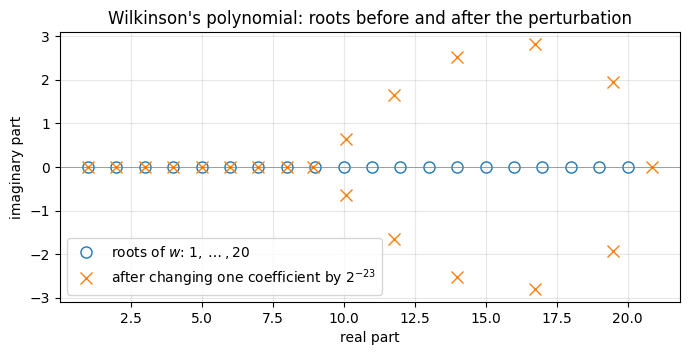

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(true_roots, np.zeros(20), "o", mfc="none", ms=8, label="roots of $w$: $1,\\dots,20$")
ax.plot(r1.real, r1.imag, "x", ms=8, label="after changing one coefficient by $2^{-23}$")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("real part"); ax.set_ylabel("imaginary part")
ax.set_title("Wilkinson's polynomial: roots before and after the perturbation")
ax.legend(loc="lower left"); ax.grid(alpha=0.3)
plt.show()

The roots $10,\dots,19$ have become **five complex pairs**; the pair born from $16$ and $17$ sits at
about $16.73 \pm 2.81\,i$, almost $3$ away from the real axis.

### Why: a first-order estimate

If the coefficient of $t^{19}$ changes by $\delta$, the root $k$ moves by approximately

$$
\delta\lambda_k \approx -\frac{\delta\, k^{19}}{w'(k)}, \qquad w'(k) = \prod_{j \ne k} (k - j).
$$

The factor $k^{19}/|w'(k)|$ is the *condition number* of the root $k$ with respect to this coefficient.

In [6]:
sens = []
for k in true_roots:
    wprime = math.prod(int(k) - j for j in range(1, 21) if j != k)
    sens.append(int(k) ** 19 / abs(wprime))
sens = np.array(sens)

for k, s in zip(true_roots, sens):
    print(f"k = {k:2d}:  k^19/|w'(k)| = {s:9.2e}   predicted shift for delta = 2^-23: {s * delta:9.2e}")

k =  1:  k^19/|w'(k)| =  8.22e-18   predicted shift for delta = 2^-23:  9.80e-25
k =  2:  k^19/|w'(k)| =  8.19e-11   predicted shift for delta = 2^-23:  9.76e-18
k =  3:  k^19/|w'(k)| =  1.63e-06   predicted shift for delta = 2^-23:  1.95e-13
k =  4:  k^19/|w'(k)| =  2.19e-03   predicted shift for delta = 2^-23:  2.61e-10
k =  5:  k^19/|w'(k)| =  6.08e-01   predicted shift for delta = 2^-23:  7.24e-08
k =  6:  k^19/|w'(k)| =  5.82e+01   predicted shift for delta = 2^-23:  6.94e-06
k =  7:  k^19/|w'(k)| =  2.54e+03   predicted shift for delta = 2^-23:  3.03e-04
k =  8:  k^19/|w'(k)| =  5.97e+04   predicted shift for delta = 2^-23:  7.12e-03
k =  9:  k^19/|w'(k)| =  8.39e+05   predicted shift for delta = 2^-23:  1.00e-01
k = 10:  k^19/|w'(k)| =  7.59e+06   predicted shift for delta = 2^-23:  9.05e-01
k = 11:  k^19/|w'(k)| =  4.64e+07   predicted shift for delta = 2^-23:  5.54e+00
k = 12:  k^19/|w'(k)| =  1.99e+08   predicted shift for delta = 2^-23:  2.37e+01
k = 13:  k^19/|w'(k)| =  6.0

For $k$ around $14$–$17$ the amplification exceeds $10^9$: the *linear* estimate predicts shifts in the
hundreds, far beyond the spacing $1$ between neighbouring roots. Long before that, neighbouring roots
collide and leave the real axis as complex pairs, which is what we saw. The estimate is not accurate here,
but it shows the size of the amplification.

## 3. The same numbers as eigenvalues of $A$

Now perturb the **entries** of $A = \operatorname{diag}\{1,\dots,20\}$ by a random matrix $E$ and call `numpy.linalg.eig`.
For this $A$, every eigenvalue of $A + E$ lies within $\|E\|_2$ of an eigenvalue of $A$
(Bauer–Fike with $P = I$).

In [7]:
rng = np.random.default_rng(0)
A = np.diag(true_roots.astype(float))

print(" ||E||_2     largest eigenvalue shift")
for size in [1e-7, 1e-4, 1e-2]:
    E = rng.standard_normal((20, 20))
    E *= size / np.linalg.norm(E, 2)            # scale so that ||E||_2 = size
    lam = np.linalg.eigvals(A + E)
    shift = max(np.min(np.abs(lam - k)) for k in true_roots)
    print(f"{size:8.0e}    {shift:.2e}")

 ||E||_2     largest eigenvalue shift
   1e-07    2.08e-08
   1e-04    2.84e-05
   1e-02    3.58e-03


The eigenvalue shifts never exceed $\|E\|_2$: as functions of the **entries**, these eigenvalues are perfectly
well behaved. As functions of the **coefficients** of $p_A$ they are wildly ill conditioned.

## Takeaways

* Forming $p_A$ replaces a well-conditioned problem (eigenvalues from entries) by an ill-conditioned one
  (roots from coefficients). The damage is done before any root finder runs.
* Ordinary rounding, with no deliberate perturbation, already costs about 15 digits on this route (Part 1).
* `numpy.linalg.eig` works with the matrix directly: Hessenberg reduction plus the shifted $QR$ algorithm
  (Lecture 3.2). Ironically, `np.roots` goes the other way: it builds the *companion matrix* of the
  polynomial and computes its eigenvalues.

**Try it.** Change a different coefficient (for instance the constant term) by the same relative amount.
Which roots move most? Does the sensitivity table predict it?